# Optimization of the Price for Heating Domestic Hot Water

To determine the market price of electricity, economists rely on **supply-and-demand** models. These models are calculated one day in advance (*day-ahead* models). In this simplified model, we consider:

- $\displaystyle \mathrm{Supply}(P) = a\,e^{\,P/b} + c$
    - This function represents the price per MWh that electricity producers are willing to offer for total production level $P$ (in MW). It is an **increasing** function: the cheapest power plants (merit order) are dispatched first, followed by progressively more expensive ones.
- $\displaystyle \mathrm{Demand}(P; h) = A\left(\frac{1}{\pi}\arctan\!\left(s\,(P - P_0(h))\right) + \frac{1}{2}\right)$
    - This function represents the maximum price consumers are willing to pay for total demand $P$ (in MW) at hour $h$ of the day.
- The reference demand $P_0(h)$ varies sinusoidally to capture two daily peaks: one in the morning and another before dinner, so that $P_0(h) = P_0 + B\sin(4\pi h/24)$.

**Parameters** *(illustrative values)*:
| Parameter | Value                             | Meaning                                                                       |
| --------- | --------------------------------- | ----------------------------------------------------------------------------- |
| $a$     | $100$ €/MWh                    | Supply curve scaling factor                                                   |
| $b$     | $5\,000$ MW                     | Supply exponential growth rate                                                |
| $c$     | $-500$ €/MWh                   | Base/intercept price, negative since it's difficult to turn power plants off. |
| $A$     | $1\,400$ €/MWh                 | Maximal demand price                                                          |
| $s$     | $-9.3\times 10^{-4}$ MW $^{-1}$ | Demand steepness (arg $s\,(P-P_0)$ dimensionless)                           |
| $P_0$   | $13\,000$ MW                    | Baseline reference total demand                                               |
| $B$     | $1\,500$ MW                     | Amplitude of hourly demand variation (sinusoidal, two peaks per day)          |

In [ ]:
# ============================================================
# Parameters (from the problem statement)
# ============================================================
a  = 100.0      # euros/MWh
b  = 5000.0     # MW
c  = -500.0     # euros/MWh
A  = 1400.0     # euros/MWh
s  = -9.3e-4    # MW^-1
P0 = 13000.0    # MW
B  = 1500.0     # MW

In [ ]:
# ============================================================
# Supply and Demand functions
# ============================================================

import numpy as np

def supply(P):
    """Supply curve: price per MWh for total production P."""
    return ....


def demand(P, h):
    """Demand curve: max price consumers willing to pay for total demand P at hour h."""
    P0h = ...
    return ....

The market price is determined at the **intersection of supply and demand**: $\mathrm{Supply}(P) = \mathrm{Demand}(P; h)$. 

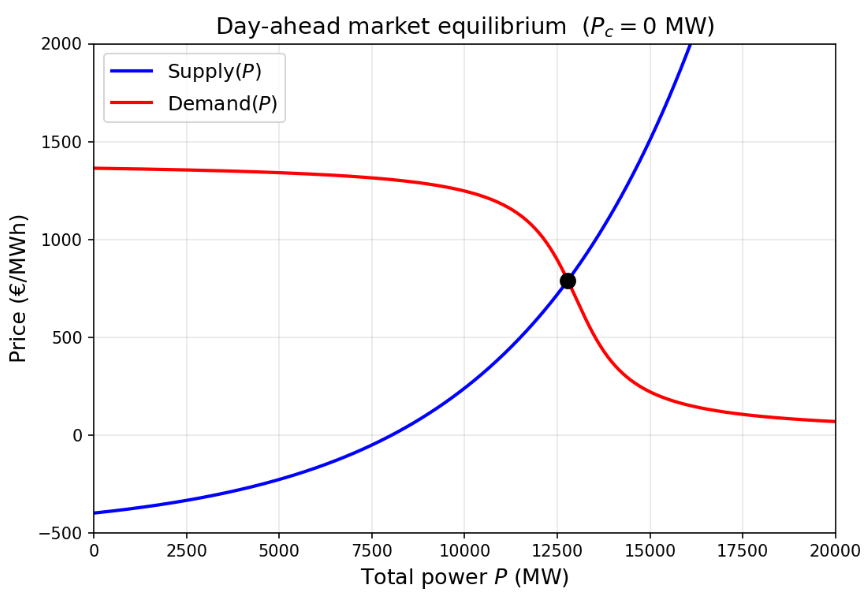

Because $P_0$ varies sinusoidally throughout the day, the demand curve shifts continuously, producing two price peaks: one in the morning and another before dinner. We illustrate how the market prixe evolves when the demand increases:

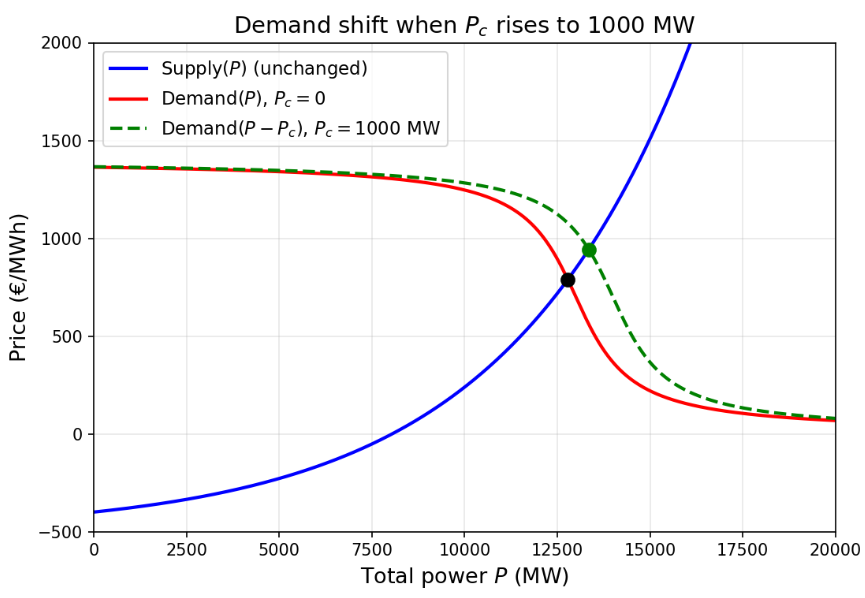

We consider a company that manages the heating of domestic hot water in a country. The supply and demand functions described above do **not** account for this enterprise's electricity consumption.

---

## Part 1) Determining the Market Price

We denote by $P_c$ the electrical power consumed by the company.

---
### Question 1) Supply and demand

**Is the $\mathrm{Demand}$ function modified? Is the $\mathrm{Supply}$ function modified?**

> **Answer:** 
>
> TODO

We are interested in the **market price** $p$ (in €/MWh), which comes from the total production $P$ that is implicitly defined via $S(P, P_c, h) = 0$. 


---
### Question 2) State equation

**Give the state function $S$, whose zero yields the equilibrium production $P$ at each hour $h$.**


> **Answer:**  
>
> TODO

In [ ]:
def S(P, Pc, h):
    "State function"
    return supply(P) - demand(P - Pc, h)

---

### Question 3) Partial Derivatives

**3.1. $\partial_P \,\mathrm{Supply}$**

> **Answer:**
>
> TODO

In [ ]:
def dsupply_dP(P):
    """d(Supply)/dP = (a/b) * exp(P/b)."""
    return ...


**3.2. $\partial_P\,\mathrm{Demand}$**, with $\arctan'(x) = \frac{1}{1+x^2}$:

> **Answer:**  
>
> TODO

In [ ]:
def ddemand_dP(P, h):
    """d(Demand)/dP = (A*s/pi) / (1 + s^2*(P - P0(h))^2)."""
    P0h = ...
    return ...


**3.3. $\partial_P\,S$**

> **Answer:**
>
> TODO


In [ ]:
def dS_dP(P, Pc, h):
    "Derivative of state function"
    return ...

---

### Question 4) Newton's Method at $P_c = 0$

**Using Newton's method, determine the equilibrium $P(P_c)$ and the market price $p(P(P_c))$ at $h=0$ when $P_c = 0$.**


In [ ]:
def newton(res,
           dres, 
           x0=0,
           tol = 1e-10,
           maxit = 100):
    "Newton solver"

    x = [x0]
    for _ in range(maxit):
        # Descent direction
        r = ... # residual
        d = ... # descent direction
        
        # Stop criterion
        if ...:
            return x
        
        # Basic line-search
        i = 0
        while ...:
            i+=1
            if i>10:
                break
        
        # update
        x.append(...)
    print("Maximum Newton iteration reached")
    return x

def P(Pc,h):
    "Market power"
    def res(P):
        "residual"
        return ...
    def dres(P):
        "residual derivative"
        return ...
    return newton(res, dres, x0 = P0)[-1]
    
def p(P):
    "Market price"
    return ...

P_ref = P(Pc=0,h=0)
p_ref = p(P_ref)

print(f"{P_ref = :.0f} MW")
print(f"{p_ref = :.0f} €/MWh")

---

### Question 5) Market reaction to increasing demand

**Determine the power $P(P_c)$ and the market price $p(P(P_c))$ at equilibrium when $h=0$ and $P_c = 1000$ MW. Comment.**


In [ ]:
P_1000 = ...
p_1000 = ...

print(f"{P_1000 = :.0f} MW")
print(f"{p_1000 = :.0f} €/MWh")

> **Answer:**
> 
> TODO!

---

### Question 6) Sensitivity of $P$ with Respect to $P_c$

#### 6.1. Using the chain rule, give the expression for $\frac{dP}{dP_c}$ at hour $h$



> **Answer:**
>
> TODO


#### 6.2. Deduce the expression for $\frac{dp_h}{dP_c}$ at hour $h$.

> **Answer:**
> 
> TODO

In [ ]:
def dp_dPc(P,h):
    "Market price derivative with respect to Pc"
    return ...

#### 6.3. Numerical application for $P_c = 0$ at $h=0$.


In [ ]:
Pc_ref = 0
h_ref = 0
dp_dPc_ref = ...
print(f"{dp_dPc_ref = :.3e} €/MWh / MW")



---

### Question 7) Verification

**Verify your expression for $\frac{dp_h}{dP_c}$ using the method you consider most appropriate.**

In [ ]:
...

---

## Part 2) Minimizing the electricity price

We consider a company that manages the heating of domestic hot water at country-scale.

- Over the next 24 hours, it chooses an hourly consumption profile $P_{c,0}, P_{c,1}, \ldots, P_{c,23}$.
- At each hour $h$, the market-clearing price $p_h$ is determined independently by the equilibrium condition $S(P_h, P_{c,h}; h) = 0$ established in Part 1, where the demand function varies sinusoidally: $P_0(h) = P_0 + B\sin(4\pi h/24)$. When $P_c$ increases, the price also increases.
- Due to this sinusoidal variation, the **baseline prices** $p_h(0)$ vary throughout the day.
- The company aims to distribute a **fixed daily energy budget** $E_{\text{total}}$ (MWh) across the 24 hours to **minimize its total electricity cost**, taking advantage of the hourly price variation.
- It should also **respect the physical limits** of electicity consumption: $0 \leq P_{c,h} \leq P_{\max}$ for each hour.

---
### Question 8) Objective Function

**Determine the objective function to minimize, accounting for hourly price variation.**



> **Answer:** 
>
> TODO

In [ ]:
def J(Pc_vec):
    "Objective function to minimize: daily cost of electricity"
    ...
    return ...

Pc_vec = [1]*24
print(f"{J(Pc_vec) = :.0f} €")


---

### Question 9) Practicality of the Q6 Method for 24 Hours

**Is the method in Question 6 practical for computing gradients in the 24-hour setting?**

> **Answer:**
> 
> TODO


---

### Question 10) Adjoint (Backward) Method

#### 10.1. Compute $\frac{dJ}{dP_{c,h}}$ using the adjoint method.

> **Answer:**
>
> TODO


#### 10.2. Comment on the efficiency.

> **Answer:**
>
> TODO

Anyway, we continue with the so-called direct approach (forward derivative computation).

In [ ]:
def dJ_dPc(Pc_vec):
    "Derivative of objective function"
    ...
    return ...

---

### Question 11) Formulate the optimization problem.

The components were described in the problem statement above; your task is to put them into a clean mathematical form.

> **Answer:**
> 
> TODO

---

### Question 12) Solve using a penalty method.

> **Answer:**
> 
> TODO

In [ ]:
def penalizedJ(Pc_vec, mu, Etot):
    "Penalized objective function"
    return ...

def d_penalizedJ_dPc(Pc_vec, mu, Etot):
    "Gradient of penalized objective function"
    return ...

In [ ]:
mu=10000
P_min = 0
P_max = 3000
Etot= 25e3
Pc_init = [Etot/24]*24

from scipy.optimize import minimize
result = ...

print(f"Jinit = {J(Pc_init)/1e3:.0f} k€/day | E = {np.sum(Pc_init):.0f} MWh ")
print(f"Jopt  = {J(result.x)/1e3:.0F} k€/day | E = {np.sum(result.x):.0f} MWh")
import matplotlib.pyplot as plt
plt.plot(result.x); plt.grid()
plt.xlabel("h"); plt.ylabel("$P_c$ (MW)")
plt.show()

---

### Question 13. Solve using the augmented Lagrangian. Why is it mathematically better?

> **Augmented Lagrangian:**
> 
> TODO

In [ ]:
def L_rho(Pc_vec, lam, rho, Etot):
    "Augmented lagrangian"
    return ...

def L_rho_grad(Pc_vec, lam, rho, Etot):
    "Gradient of Augmented lagrangian"
    return ...

In [ ]:
def augmented_lagrangian(Pc_vec0, lam0, rho, Etot, maxit = 20):
    ...
    
    return ...

Pc_opt, lam_opt = augmented_lagrangian(Pc_vec0 = Pc_init, 
                     lam0 = 0, 
                     rho = 1, 
                     Etot = Etot, 
                     maxit = 50)

In [ ]:
print(f"Jinit = {J(Pc_init)/1e3:.0f} k€/day | E = {np.sum(Pc_init):.0f} MWh ")
print(f"Jopt  = {J(Pc_opt[-1])/1e3:.0F} k€/day | E = {np.sum(Pc_opt[-1]):.0f} MWh")
import matplotlib.pyplot as plt
plt.plot(result.x); plt.grid()
plt.xlabel("h"); plt.ylabel("$P_c$ (MW)")
plt.show()


---

### Question 15. Interpret the Lagrange multiplier.

#### 15a. What is the unit of $\lambda$?

In [ ]:
plt.plot(lam_opt)
plt.ylabel(...) # todo unit
plt.grid()
plt.show()

#### 15b. Write the KKT condition. What is the economic interpretation of $\lambda$?

> **Answer:**
>
> TODO

#### 15c. How does the optimal cost change when we change the budget?

We expect to evaluate $\frac{dJ(P_c^*)}{dE_{tot}}$, with $P_c^*$ the optimal power consumption satisfying the constraints.

> **Answer:**
>
> TODO

---
### Question 16) What if the bound constraints are active?

> **Answer:**
>
> TODO

---
### Question 17) Propose a dual optimization algorithm that optimize $\lambda$ instead of $P_c$. Comments.

> **Answer:**
>
> TODO

In [ ]:
# Now it's your time to play!